# 01 — Exploratory Data Analysis: Indian city-day air quality (2015–2020)

**Question.** Can we forecast tomorrow's PM2.5 for a city, and flag "Poor or worse" days (PM2.5 > 90 µg/m³) 24 h ahead?

**Goals.** (1) ≥15% lower MAE than the persistence baseline on 2020. (2) Recall ≥ 0.80 with precision ≥ 0.60 for Poor+ days.

**Data.** CPCB station data aggregated per city-day, via Kaggle `rohanrao/air-quality-data-in-india` (`city_day.csv`).

Run from `partA-project/` after `python -m src.download_data` and `python -m src.clean` (or simply `python -m src.run_all`).

In [1]:
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # so `src` imports work from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

from src.config import RAW_FILE, CLEAN_FILE, CLEANING_REPORT, FIGURES, POOR_THRESHOLD, SEED, TRAIN_YEARS

np.random.seed(SEED)
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def save(name): plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. First look at the raw data

In [2]:
raw = pd.read_csv(RAW_FILE, parse_dates=["Date"])
print(raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype").T)
raw.describe().T.round(1)

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
dtype,object,datetime64[ns],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,object


,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118080,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


Cities: 26
Date range: 2015-01-01 to 2020-07-01
Duplicate (City, Date) rows: 0


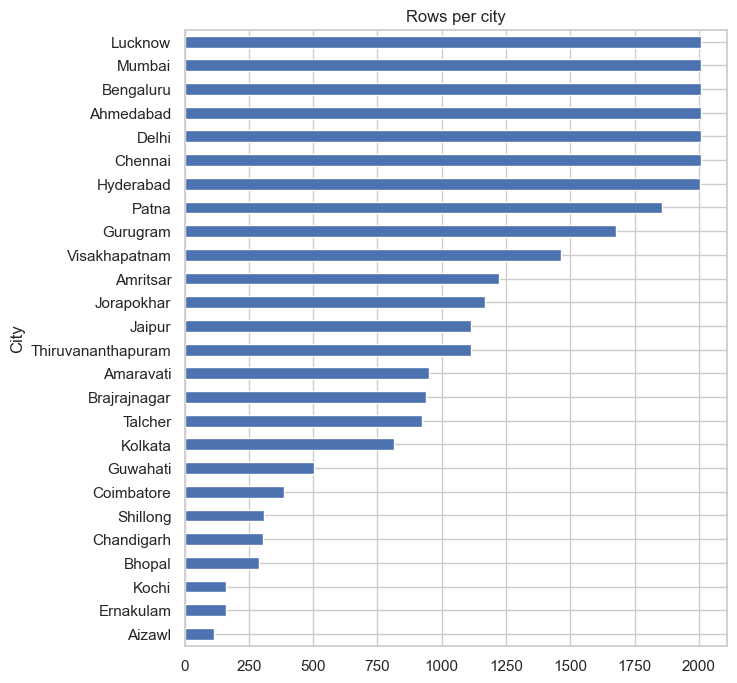

In [3]:
print("Cities:", raw.City.nunique())
print("Date range:", raw.Date.min().date(), "to", raw.Date.max().date())
print("Duplicate (City, Date) rows:", raw.duplicated(["City", "Date"]).sum())
raw.groupby("City").size().sort_values().plot.barh(figsize=(7, 8), title="Rows per city")
save("rows_per_city"); plt.show()

**Insight:** 26 cities, 2015-01-01 to 2020-07-01, no duplicate (City, Date) rows. Coverage is very uneven: Delhi, Lucknow, Chennai, Hyderabad and Bengaluru have ~2,000 days each, while Aizawl, Kochi and Ernakulam start only in 2020 and Bhopal, Chandigarh, Shillong, Coimbatore and Guwahati in 2019.
**Decision:** a time-based split will contain cities in val/test that never appear in training, so the model must not rely on a city identifier. City level comes from each city's own past values (lags, rolling means, expanding mean) instead of a one-hot or target-encoded city ID.

## 2. Missing values

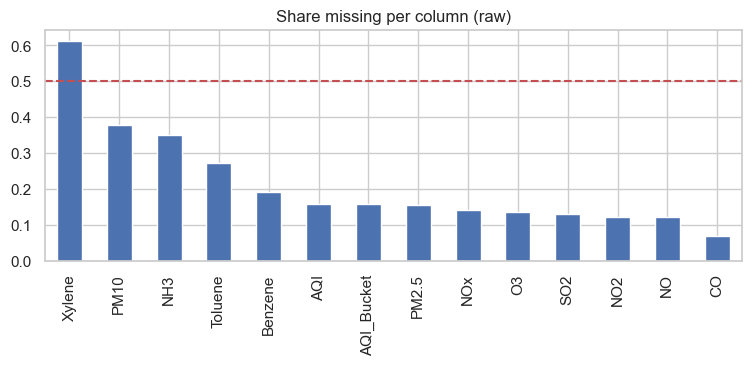

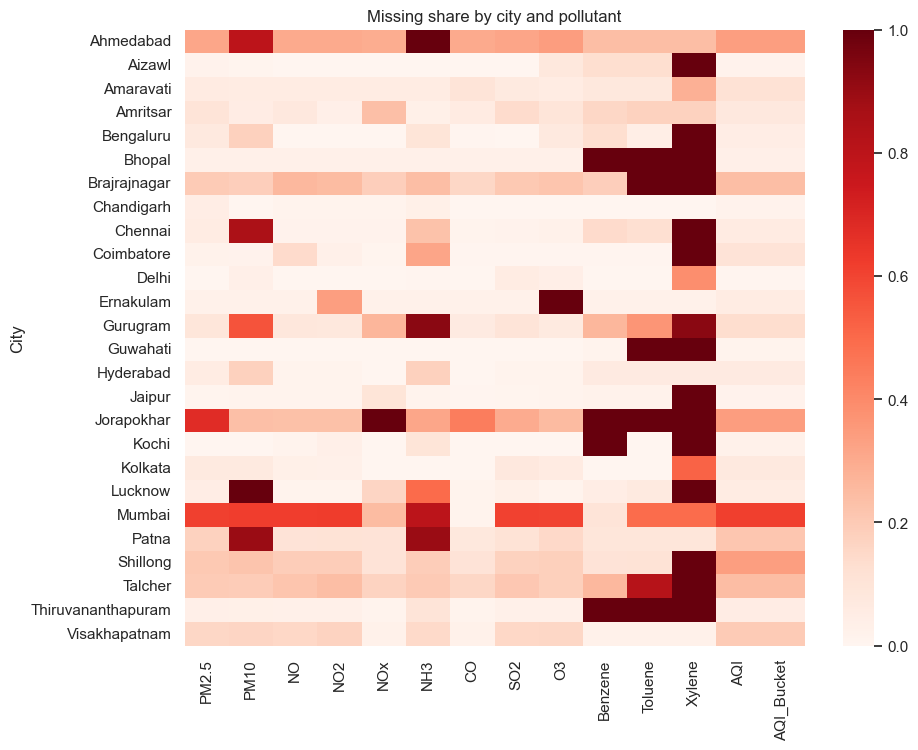

In [4]:
miss = raw.drop(columns=["City", "Date"]).isna().mean().sort_values(ascending=False)
miss.plot.bar(figsize=(9, 3), title="Share missing per column (raw)"); plt.axhline(0.5, ls="--", c="r")
save("missing_share"); plt.show()

by_city = raw.drop(columns=["Date"]).groupby("City").agg(lambda s: s.isna().mean())
plt.figure(figsize=(10, 8)); sns.heatmap(by_city, cmap="Reds", vmin=0, vmax=1)
plt.title("Missing share by city and pollutant"); save("missing_heatmap"); plt.show()

**Insight:** missingness is mostly *structural*, not random: whole stations never measured some pollutants (e.g. Xylene is entirely missing in more than 10 cities, Benzene/Toluene in Bhopal, Thiruvananthapuram, Jorapokhar), and Mumbai is ~60% missing across the board. PM10 (54% missing in train years) and Xylene (61%) are too sparse to be reliable.
**Decision:** drop PM10 and Xylene (threshold 50%, measured on train years only). For the rest, forward-fill gaps of ≤3 days within each city (past values only) and add a `*_was_missing` flag so the model can learn that "not measured" differs from "low". The target is never imputed.

## 3. Cleaning summary
`src/clean.py` applies the rules (each one is justified in its docstring). The numbers below come from `reports/cleaning_report.json`.

In [5]:
report = json.loads(Path(CLEANING_REPORT).read_text())
for k in ["raw_rows", "rows_missing_city_or_date", "duplicate_city_date_rows",
          "dropped_sparse_columns", "calendar_rows_added", "clean_rows"]:
    print(f"{k:28s} {report[k]}")
pd.DataFrame({"impossible -> NaN": report["impossible_values_set_to_nan"],
              "forward-filled": report["ffilled_values"],
              "still missing": report["still_missing_after_ffill"]})

raw_rows                     29531
rows_missing_city_or_date    0
duplicate_city_date_rows     0
dropped_sparse_columns       ['PM10', 'Xylene']
calendar_rows_added          0
clean_rows                   29531


,impossible -> NaN,forward-filled,still missing
PM2.5,0,522.0,4092.0
PM10,0,NaN,NaN
NO,0,602.0,2980.0
NO2,0,601.0,2984.0
NOx,0,392.0,3793.0
NH3,0,516.0,9812.0
CO,120,708.0,1471.0
SO2,0,685.0,3169.0
O3,0,711.0,3311.0
Benzene,35,647.0,5011.0


In [6]:
df = pd.read_csv(CLEAN_FILE, parse_dates=["Date"])
df["year"], df["month"] = df.Date.dt.year, df.Date.dt.month
df["poor"] = (df["PM2.5_obs"] > POOR_THRESHOLD).astype("Int8").where(df["PM2.5_obs"].notna())
df.shape

(29531, 28)

## 4. Outliers: impossible vs real extremes

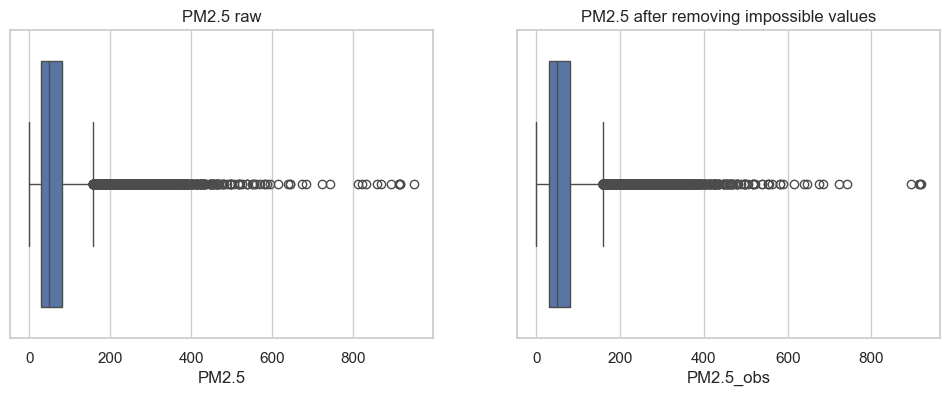

,City,Date,PM2.5_obs
25729,Shillong,2019-09-03,917.77
12504,Gurugram,2016-03-10,914.94
25728,Shillong,2019-09-02,914.64
12511,Gurugram,2016-03-17,894.75
19924,Lucknow,2015-03-20,742.67
12995,Gurugram,2017-07-14,723.16
10904,Delhi,2016-11-06,685.36
19926,Lucknow,2015-03-22,674.43
24066,Patna,2015-12-20,645.50
11271,Delhi,2017-11-08,639.19


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
sns.boxplot(x=raw["PM2.5"], ax=ax[0]); ax[0].set_title("PM2.5 raw")
sns.boxplot(x=df["PM2.5_obs"], ax=ax[1]); ax[1].set_title("PM2.5 after removing impossible values")
save("pm25_boxplots"); plt.show()
df.nlargest(10, "PM2.5_obs")[["City", "Date", "PM2.5_obs"]]  # are these Diwali / Nov stubble-burning days?

**Insight:** no PM2.5 value is negative or above the physical cap, but the raw boxplot shows a long tail up to ~950 µg/m³. The top values are a mix: Gurugram in Nov 2016 is the well-documented Delhi-NCR smog episode (real), whereas Gurugram at 950 in late August, Guwahati at 917 in May or Amritsar at 869 in May (next to days around 30–40) have no plausible cause.
**Decision:** keep extremes in the Oct–Jan smog/festival season (they are what we want to predict), but set off-season readings >300 that are >6× the city's previous-30-day median to NaN (16 readings, listed in `cleaning_report.json`). The rule uses only past data, so it cannot leak future information. CO, Benzene and Toluene had 177 values above physical caps, also set to NaN.

## 5. Target distribution and class balance

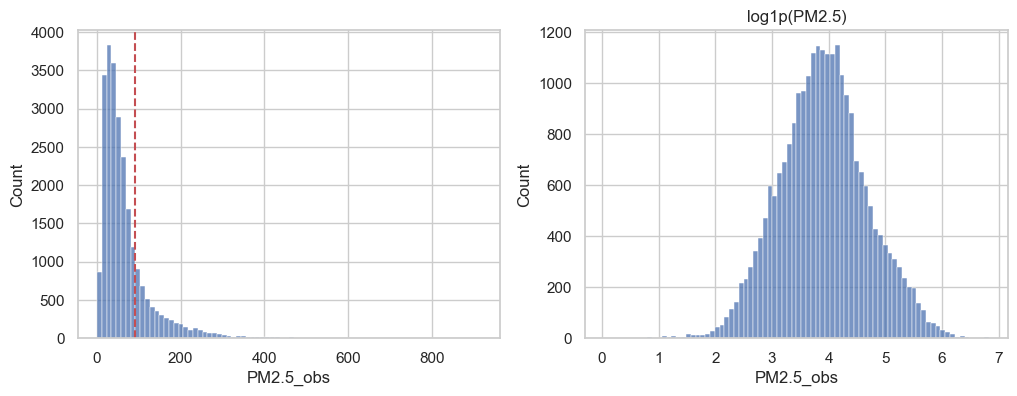

Poor+ share overall: 0.209


year
2015    0.292
2016      0.3
2017    0.313
2018    0.225
2019    0.169
2020    0.087
Name: poor, dtype: Float64

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["PM2.5_obs"], bins=80, ax=ax[0]); ax[0].axvline(POOR_THRESHOLD, c="r", ls="--")
sns.histplot(np.log1p(df["PM2.5_obs"]), bins=80, ax=ax[1]); ax[1].set_title("log1p(PM2.5)")
save("pm25_hist"); plt.show()
print("Poor+ share overall:", round(df.poor.mean(), 3))
df.groupby("year").poor.mean().round(3)

**Insight:** PM2.5 is strongly right-skewed (median ≈ 50, long tail to several hundred); on a log scale it is roughly symmetric. About 21% of city-days are Poor+ (> 90 µg/m³), but the share falls from ~30% in 2015–17 to ~17% in 2019 and only ~9% in 2020.
**Decision:** (1) report MAE (robust to the tail) *and* RMSE (sensitive to spikes); (2) for the Poor+ flag use precision/recall/PR-AUC, not accuracy, and pick the threshold on 2019; (3) expect the 2020 test year to be easier on MAE but harder for the classifier because positives are rare.

## 6. Seasonality and city differences

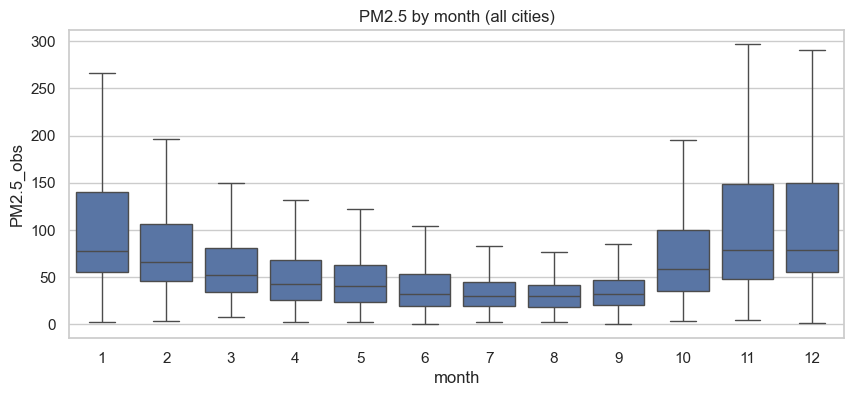

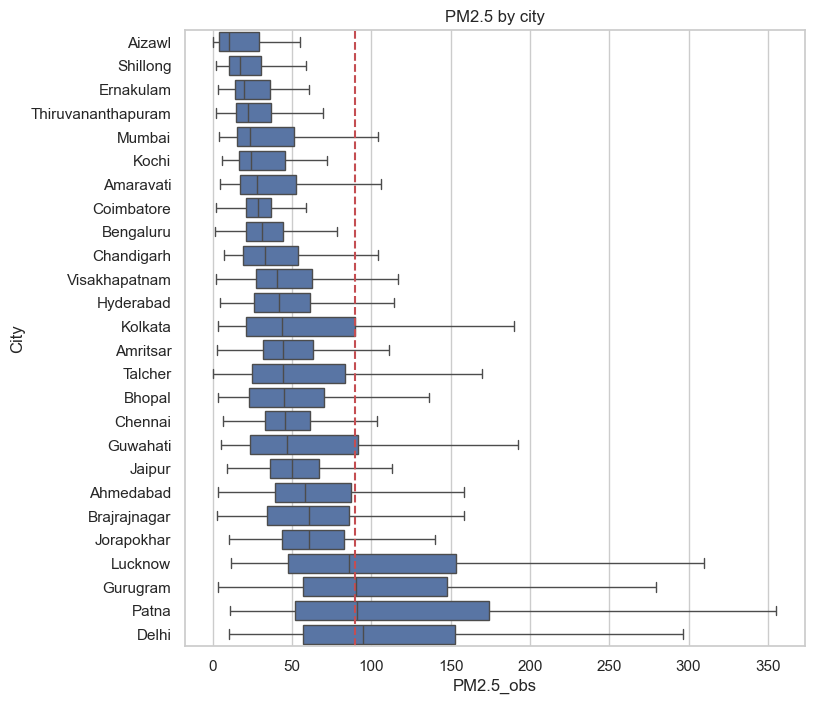

In [9]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="month", y="PM2.5_obs", showfliers=False)
plt.title("PM2.5 by month (all cities)"); save("pm25_by_month"); plt.show()

order = df.groupby("City")["PM2.5_obs"].median().sort_values().index
plt.figure(figsize=(8, 8))
sns.boxplot(data=df, y="City", x="PM2.5_obs", order=order, showfliers=False)
plt.axvline(POOR_THRESHOLD, c="r", ls="--"); plt.title("PM2.5 by city")
save("pm25_by_city"); plt.show()

**Insight:** a clear U-shaped season: medians ~75–80 µg/m³ in Nov–Jan versus ~30 in Jul–Sep (monsoon rain washes particles out; winter inversions trap them). Cities differ by a factor of ~5: Delhi, Patna, Gurugram and Lucknow have medians near the Poor+ line, while Aizawl, Shillong and the Kerala cities are around 15–25.
**Decision:** add season, month and smooth day-of-year (sin/cos) features of the *target* day, a Diwali-window flag, and a per-city level feature (30-day rolling mean and expanding past mean) rather than a city ID.

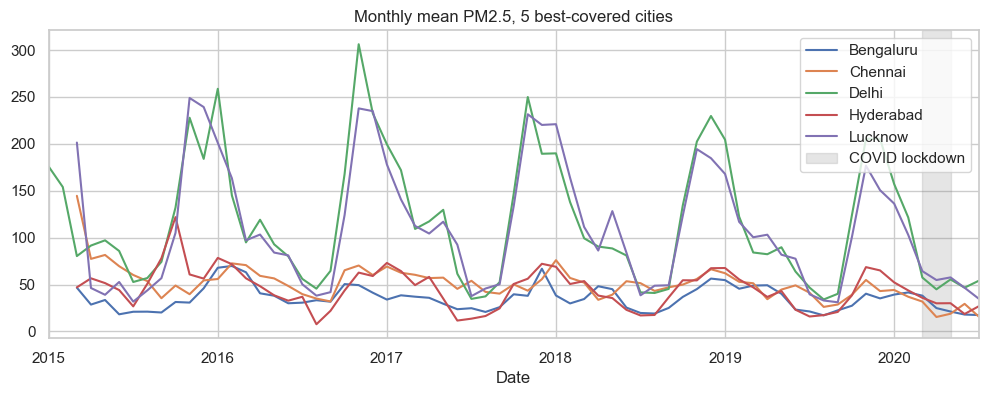

In [10]:
top = df.groupby("City")["PM2.5_obs"].count().nlargest(5).index
m = df[df.City.isin(top)].set_index("Date").groupby("City")["PM2.5_obs"].resample("MS").mean().unstack(0)
m.plot(figsize=(12, 4), title="Monthly mean PM2.5, 5 best-covered cities")
plt.axvspan("2020-03-25", "2020-05-31", color="grey", alpha=0.2, label="COVID lockdown")
plt.legend(); save("pm25_timeseries"); plt.show()

**Insight:** the seasonal cycle repeats every year, with the North Indian cities (Delhi, Lucknow) peaking at 200–300 each winter while the southern cities stay flat around 30–70. The winter peaks are slowly getting lower, and 2020 drops sharply after the 25 March COVID lockdown.
**Decision:** split by time (train 2015–18, val 2019, test 2020), never randomly, so the evaluation mimics real forecasting. The lockdown is a genuine distribution shift inside the test year; error analysis reports before- and after-lockdown errors separately.

## 7. Relationships between pollutants (train years only)

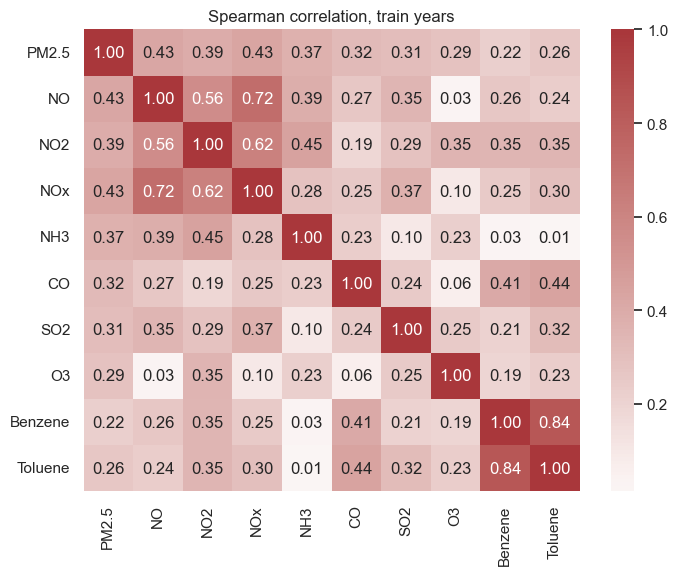

In [11]:
lo, hi = TRAIN_YEARS
pols = [c for c in df.columns if c in report["missing_share_train"] and c in df.columns]
corr = df[df.year.between(lo, hi)][pols].corr(method="spearman")
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Spearman correlation, train years"); save("corr_heatmap"); plt.show()

**Insight:** PM2.5 correlates only moderately with the other pollutants (Spearman 0.2–0.45; strongest with NO/NOx ≈ 0.43, the traffic/combustion markers). Benzene–Toluene (0.84) and NO–NOx (0.72) are near-duplicates.
**Decision:** other pollutants are kept as weak same-day features; tree models cope with the collinearity and Ridge's L2 penalty shrinks redundant coefficients. They will not replace PM2.5's own history as the main signal.

## 8. Autocorrelation → justifies lag features

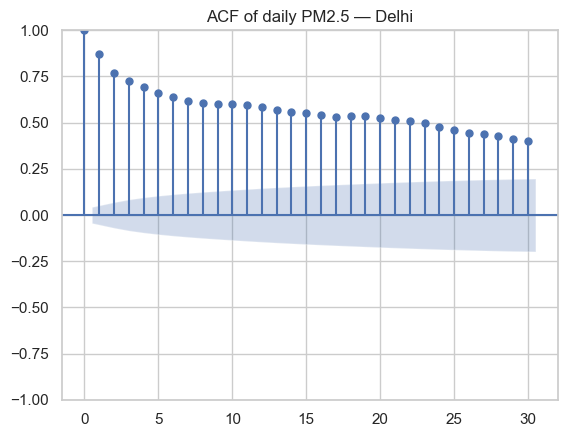

In [12]:
city = df.groupby("City")["PM2.5_obs"].count().idxmax()
s = df[df.City == city].set_index("Date")["PM2.5_obs"].interpolate(limit=3).dropna()  # plotting only
plot_acf(s, lags=30); plt.title(f"ACF of daily PM2.5 — {city}")
save("acf"); plt.show()

**Insight:** Delhi's daily PM2.5 is highly autocorrelated: ~0.87 at lag 1, ~0.77 at lag 2, and still ~0.6 after a week, decaying slowly (seasonal persistence).
**Decision:** this justifies lag-1/2/6 and 3/7/30-day rolling-mean features (all computed from day t and earlier). It also warns that **persistence** ("tomorrow = today") will be a very strong baseline: any model must be judged against it, not against a naive mean.

## 9. Summary of EDA findings → modelling decisions
- **Strong lag-1 autocorrelation (0.87)** → lag and rolling features from past days only; persistence is the baseline to beat; models predict the *change* from today.
- **Clear winter peak / monsoon trough** → season, month and day-of-year features of the target day, plus a Diwali flag.
- **5× differences between cities, and cities that appear only in 2019–20** → no city ID; city level from its own past (rolling and expanding means).
- **Structural missingness** → drop PM10/Xylene, ≤3-day past-only forward fill, `was_missing` flags, median imputation inside the model pipeline.
- **Poor+ share falls from ~30% to ~9% (2020)** → precision/recall/PR-AUC, threshold chosen on 2019, and a discussion of the 2020 shift.
- **Lockdown in the test year** → report errors before and after 25 March 2020 separately.
- **Weather drives dispersion** (rain in the monsoon, winter inversions) → join daily weather (NASA POWER) for day t; tomorrow's actual weather is used only as an "oracle forecast" ablation.